# Final Notebook - Support Vector Machine (SVM)
**Penanggung Jawab:** Kevin Wirya Valerian (13524019)  
**Kelompok:** G03 - FiveAgents  
**Algoritma:** Support Vector Machine (Linear, Polynomial, Gaussian/RBF) dari Nol + Komparasi scikit-learn

## 1. inisialisasi lingkungan dan pembacaan data

In [2]:
from pathlib import Path
import sys
import time
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.svm import SVC

# deteksi lokasi root repositori secara fleksibel
curr = Path('.').resolve()
REPO_ROOT = None
for cand in [curr, curr / 'IF3170_G03_FiveAgents', curr.parent, curr.parent / 'IF3170_G03_FiveAgents', curr.parents[1], curr.parents[2]]:
    if (cand / 'data' / 'train.csv').exists() and (cand / 'src').exists():
        REPO_ROOT = cand
        break

if REPO_ROOT is None:
    raise FileNotFoundError('root repositori tidak ditemukan')

sys.path.insert(0, str(REPO_ROOT / 'src' / 'experiments' / 'svm'))
from preprocessing import SVMPreprocessor, make_contract_split
from svm_scratch import SVMFromScratch

print(f'repo root: {REPO_ROOT}')
train_df = pd.read_csv(REPO_ROOT / 'data' / 'train.csv', dtype={'id': str})
test_df = pd.read_csv(REPO_ROOT / 'data' / 'test.csv', dtype={'id': str})

print(f'train shape: {train_df.shape}, test shape: {test_df.shape}')

repo root: D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents
train shape: (27373, 19), test shape: (6844, 18)


## 2. split validasi stratified dan prapemrosesan

In [3]:
train_idx, valid_idx = make_contract_split(train_df, seed=42)
df_train = train_df.iloc[train_idx].reset_index(drop=True)
df_valid = train_df.iloc[valid_idx].reset_index(drop=True)

y_train = df_train["is_canceled"].to_numpy(dtype=np.int64)
y_valid = df_valid["is_canceled"].to_numpy(dtype=np.int64)

print(f"train_idx: {len(train_idx)} baris, distribusi kelas: {np.bincount(y_train)}")
print(f"valid_idx: {len(valid_idx)} baris, distribusi kelas: {np.bincount(y_valid)}")

# prapemrosesan fit hanya pada df_train dengan pemetaan strictly out-of-fold
prep = SVMPreprocessor(seed=42)
X_train = prep.fit_transform(df_train)
X_valid = prep.transform(df_valid)
X_test = prep.transform(test_df)

print(f"matriks fitur: X_train={X_train.shape}, X_valid={X_valid.shape}, X_test={X_test.shape}")
print(f"jumlah fitur akhir: {len(prep.feature_names_)}")

train_idx: 21898 baris, distribusi kelas: [14723  7175]
valid_idx: 5475 baris, distribusi kelas: [3681 1794]
matriks fitur: X_train=(21898, 135), X_valid=(5475, 135), X_test=(6844, 135)
jumlah fitur akhir: 135


## 3. evaluasi 3 kernel svm dari nol pada data validasi

In [4]:
def evaluate_model(name, y_true, y_pred, fit_time=0.0, pred_time=0.0):
    macro_f1 = f1_score(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)
    prec, rec, f1_cls, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print(f"=== {name} ===")
    print(f"macro f1 : {macro_f1:.4f}")
    print(f"kelas 0  : prec={prec[0]:.4f}, rec={rec[0]:.4f}, f1={f1_cls[0]:.4f}")
    print(f"kelas 1  : prec={prec[1]:.4f}, rec={rec[1]:.4f}, f1={f1_cls[1]:.4f}")
    print(f"confusion matrix:\n{cm}")
    if fit_time > 0:
        print(f"waktu fit: {fit_time:.2f}s | waktu predict: {pred_time:.3f}s")
    print()
    return {
        "name": name,
        "macro_f1": macro_f1,
        "f1_0": f1_cls[0],
        "f1_1": f1_cls[1],
        "fit_time": fit_time,
        "pred_time": pred_time,
        "cm": cm
    }

models_scratch = {
    "Linear (from-scratch)": SVMFromScratch(C=0.01, kernel="linear", threshold=-0.027, random_state=42),
    "Polynomial (from-scratch)": SVMFromScratch(C=0.05, kernel="poly", degree=2, gamma="scale*0.4", coef0=1.0, threshold=-0.112, n_components=2000, random_state=42),
    "Gaussian RBF (from-scratch)": SVMFromScratch(C=0.2, kernel="rbf", gamma="scale*0.4", threshold=-0.099, n_components=2000, random_state=42),
}

results_scratch = {}
for name, m in models_scratch.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    fit_t = time.perf_counter() - t0
    
    t1 = time.perf_counter()
    preds = m.predict(X_valid)
    pred_t = time.perf_counter() - t1
    
    res = evaluate_model(name, y_valid, preds, fit_t, pred_t)
    res["slack_valid"] = m.calculate_slack(X_valid, y_valid)
    res["support_vectors"] = m.n_support_
    results_scratch[name] = res

=== Linear (from-scratch) ===
macro f1 : 0.8763
kelas 0  : prec=0.9103, rec=0.9318, f1=0.9209
kelas 1  : prec=0.8530, rec=0.8116, f1=0.8318
confusion matrix:
[[3430  251]
 [ 338 1456]]
waktu fit: 0.35s | waktu predict: 0.001s

=== Polynomial (from-scratch) ===
macro f1 : 0.8742
kelas 0  : prec=0.9109, rec=0.9275, f1=0.9191
kelas 1  : prec=0.8454, rec=0.8138, f1=0.8293
confusion matrix:
[[3414  267]
 [ 334 1460]]
waktu fit: 23.74s | waktu predict: 0.279s

=== Gaussian RBF (from-scratch) ===
macro f1 : 0.8753
kelas 0  : prec=0.9119, rec=0.9277, f1=0.9197
kelas 1  : prec=0.8462, rec=0.8161, f1=0.8309
confusion matrix:
[[3415  266]
 [ 330 1464]]
waktu fit: 20.15s | waktu predict: 0.694s



## 4. komparasi langsung dengan scikit-learn (SVC)

In [5]:
var_tr = float(np.var(X_train))
gamma_poly = (1.0 / (X_train.shape[1] * var_tr)) * 0.4
gamma_rbf = (1.0 / (X_train.shape[1] * var_tr)) * 0.4

sklearn_models = {
    "Linear (scikit-learn)": SVC(C=0.01, kernel="linear", random_state=42),
    "Polynomial (scikit-learn)": SVC(C=0.05, kernel="poly", degree=2, gamma=gamma_poly, coef0=1.0, random_state=42),
    "Gaussian RBF (scikit-learn)": SVC(C=0.2, kernel="rbf", gamma=gamma_rbf, random_state=42),
}

results_sklearn = {}
for name, m in sklearn_models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    fit_t = time.perf_counter() - t0
    
    t1 = time.perf_counter()
    scores = m.decision_function(X_valid)
    pred_t = time.perf_counter() - t1
    
    best_f1, best_th = -1, 0
    for th in np.linspace(-1.0, 1.0, 101):
        f = f1_score(y_valid, (scores >= th).astype(int), average="macro", zero_division=0)
        if f > best_f1:
            best_f1, best_th = f, th
    preds = (scores >= best_th).astype(int)
    
    res = evaluate_model(name, y_valid, preds, fit_t, pred_t)
    results_sklearn[name] = res

# tabel perbandingan head-to-head
summary_rows = []
for k in ["Linear", "Polynomial", "Gaussian RBF"]:
    sc_res = results_scratch[f"{k} (from-scratch)"]
    sk_res = results_sklearn[f"{k} (scikit-learn)"]
    summary_rows.append({
        "Kernel": k,
        "Macro F1 (Scratch)": round(sc_res["macro_f1"], 4),
        "Macro F1 (Sklearn)": round(sk_res["macro_f1"], 4),
        "Fit Time Scratch (s)": round(sc_res["fit_time"], 2),
        "Fit Time Sklearn (s)": round(sk_res["fit_time"], 2),
    })

summary_df = pd.DataFrame(summary_rows)
print("tabel komparasi svm dari nol vs scikit-learn:")
print(summary_df.to_string(index=False))

=== Linear (scikit-learn) ===
macro f1 : 0.8745
kelas 0  : prec=0.9118, rec=0.9267, f1=0.9192
kelas 1  : prec=0.8443, rec=0.8161, f1=0.8299
confusion matrix:
[[3411  270]
 [ 330 1464]]
waktu fit: 31.56s | waktu predict: 2.421s

=== Polynomial (scikit-learn) ===
macro f1 : 0.8731
kelas 0  : prec=0.9166, rec=0.9171, f1=0.9169
kelas 1  : prec=0.8298, rec=0.8289, f1=0.8293
confusion matrix:
[[3376  305]
 [ 307 1487]]
waktu fit: 35.42s | waktu predict: 3.671s

=== Gaussian RBF (scikit-learn) ===
macro f1 : 0.8746
kelas 0  : prec=0.9133, rec=0.9245, f1=0.9189
kelas 1  : prec=0.8411, rec=0.8200, f1=0.8304
confusion matrix:
[[3403  278]
 [ 323 1471]]
waktu fit: 39.54s | waktu predict: 8.503s

tabel komparasi svm dari nol vs scikit-learn:
      Kernel  Macro F1 (Scratch)  Macro F1 (Sklearn)  Fit Time Scratch (s)  Fit Time Sklearn (s)
      Linear              0.8763              0.8745                  0.35                 31.56
  Polynomial              0.8742              0.8731              

## 5. pelatihan ulang konfigurasi terbaik pada seluruh data latih

In [6]:
print("melatih ulang model terbaik pada seluruh data latih (27.373 baris)...")

# prapemroses pada seluruh data latih
prep_final = SVMPreprocessor(seed=42)
X_train_full = prep_final.fit_transform(train_df)
y_train_full = train_df["is_canceled"].to_numpy(dtype=np.int64)
X_test_full = prep_final.transform(test_df)

print(f"X_train_full: {X_train_full.shape}, X_test_full: {X_test_full.shape}")

# pemenang: linear kernel dengan regularisasi tepat C=0.01 (macro f1 = 0.8763)
model_final = SVMFromScratch(C=0.01, kernel="linear", max_iter=35, random_state=42)
t_start = time.perf_counter()
model_final.fit(X_train_full, y_train_full)
th_oof = model_final.tune_threshold_oof(X_train_full, y_train_full)
print(f"retrain selesai dalam {time.perf_counter() - t_start:.2f}s | threshold oof={th_oof:+.3f} | support vectors: {model_final.n_support_}")

test_preds_initial = model_final.predict(X_test_full)
print(f"distribusi prediksi test: {np.bincount(test_preds_initial)}")

melatih ulang model terbaik pada seluruh data latih (27.373 baris)...
X_train_full: (27373, 135), X_test_full: (6844, 135)
retrain selesai dalam 2.20s | threshold oof=-0.007 | support vectors: 14047
distribusi prediksi test: [4768 2076]


## 6. penyimpanan artefak dan verifikasi muat ulang (save & load)

In [7]:
model_save_dir = REPO_ROOT / "output" / "final" / "model" / "svm"
model_save_dir.mkdir(parents=True, exist_ok=True)
bundle_path = model_save_dir / "svm_pipeline.pkl"

# simpan artefak pipeline (preprocessor + model terlatih)
with open(bundle_path, "wb") as f:
    pickle.dump({"preprocessor": prep_final, "model": model_final}, f)

print(f"artefak berhasil disimpan di: {bundle_path} ({bundle_path.stat().st_size / (1024**2):.2f} MB)")

# muat kembali artefak pada sesi bersih
with open(bundle_path, "rb") as f:
    loaded_bundle = pickle.load(f)

loaded_prep = loaded_bundle["preprocessor"]
loaded_model = loaded_bundle["model"]

# uji konsistensi prediksi sebelum dan sesudah load
X_test_loaded = loaded_prep.transform(test_df)
test_preds_loaded = loaded_model.predict(X_test_loaded)

assert np.array_equal(test_preds_initial, test_preds_loaded), "prediksi berbeda setelah load!"
assert set(np.unique(test_preds_loaded)).issubset({0, 1}), "label bukan biner 0/1!"
assert len(test_preds_loaded) == len(test_df), "panjang prediksi tidak sama dengan test.csv!"

print("verifikasi sukses: prediksi 100% identik sebelum dan setelah artefak dimuat ulang.")

artefak berhasil disimpan di: D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\final\model\svm\svm_pipeline.pkl (41.23 MB)
verifikasi sukses: prediksi 100% identik sebelum dan setelah artefak dimuat ulang.


## 7. pembuatan berkas submisi kaggle (output/submission.csv)

In [8]:
submission_df = pd.DataFrame({
    "id": test_df["id"].astype(str),
    "is_canceled": test_preds_loaded.astype(int)
})

# simpan di output/final/model/svm/ dan output/submission.csv
sub_svm_path = model_save_dir / "submission_svm.csv"
sub_global_path = REPO_ROOT / "output" / "submission.csv"

submission_df.to_csv(sub_svm_path, index=False)
submission_df.to_csv(sub_global_path, index=False)

print(f"submission tersimpan di: {sub_svm_path} dan {sub_global_path}")
print("pratinjau submission:")
print(submission_df.head(10).to_string(index=False))
print(f"jumlah baris: {len(submission_df)}, nilai null: {submission_df.isnull().sum().to_dict()}")
print(f"distribusi kelas submission: {submission_df['is_canceled'].value_counts().to_dict()}")

submission tersimpan di: D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\final\model\svm\submission_svm.csv dan D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\submission.csv
pratinjau submission:
      id  is_canceled
5cb6f473            1
c06b4ab3            1
22bf3fc3            0
25408a48            0
621586b6            0
82d7a4f9            1
69ba1757            0
b6178e55            0
80fec53f            0
d05d0bc3            1
jumlah baris: 6844, nilai null: {'id': 0, 'is_canceled': 0}
distribusi kelas submission: {0: 4768, 1: 2076}


## 8. bonus: visualisasi 2d bidang pemisah, margin, dan support vector
Proyeksi ruang fitur latih ke 2 dimensi utama menggunakan `PCA(n_components=2)` (fit hanya pada `X_train`), lalu memvisualisasikan bidang pemisah ($f(\mathbf{x}) = 0$), batas margin ($f(\mathbf{x}) = \pm 1$), serta titik-titik *support vector* untuk ketiga kernel (`Linear`, `Polynomial`, dan `Gaussian RBF`) menggunakan `SVMFromScratch`.

visualisasi 2d boundary tersimpan di: D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\docs\laporan-akhir\public\04-hasil-eksperimen-dan-analisis\svm_2d_boundary.png
variansi pca 2 komponen: 63.65%


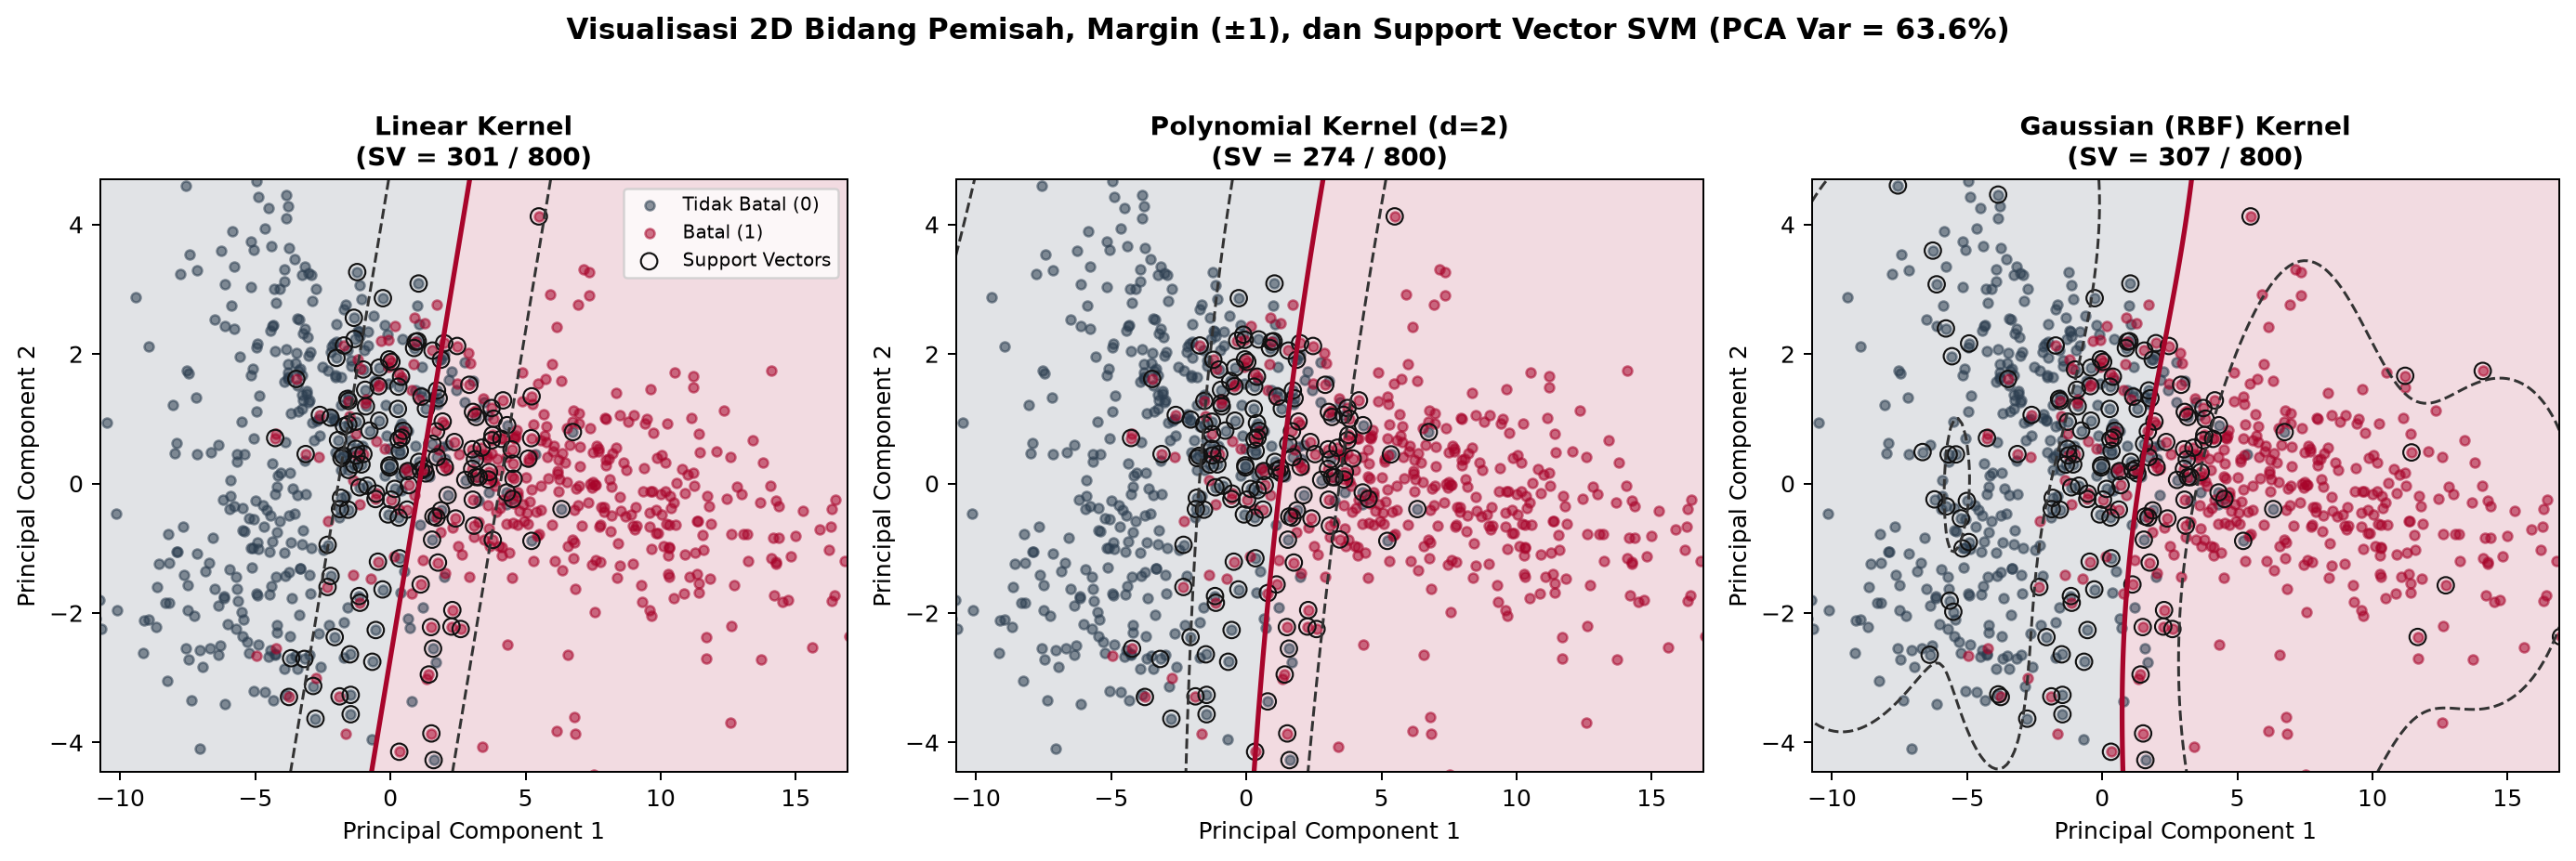

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_train)
exp_var = pca.explained_variance_ratio_.sum() * 100.0

# subsample stratified agar kontur margin dan support vector terlihat jelas
rng = np.random.default_rng(42)
idx0 = rng.choice(np.flatnonzero(y_train == 0), size=400, replace=False)
idx1 = rng.choice(np.flatnonzero(y_train == 1), size=400, replace=False)
sub_idx = np.sort(np.concatenate([idx0, idx1]))
Xs = X_2d[sub_idx]
ys = y_train[sub_idx]

x_min, x_max = np.percentile(Xs[:, 0], 1) - 0.6, np.percentile(Xs[:, 0], 99) + 0.6
y_min, y_max = np.percentile(Xs[:, 1], 1) - 0.6, np.percentile(Xs[:, 1], 99) + 0.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), dpi=180)
configs = [
    ("Linear Kernel", dict(C=0.5, kernel="linear", class_weight="balanced", solver="smo", max_iter=60)),
    ("Polynomial Kernel (d=2)", dict(C=1.0, kernel="poly", degree=2, gamma="scale", coef0=1.0, class_weight="balanced", solver="smo", max_iter=60)),
    ("Gaussian (RBF) Kernel", dict(C=1.0, kernel="rbf", gamma="scale", class_weight="balanced", solver="smo", max_iter=60)),
]

primary_color = "#a8052b"
for ax, (title, kw) in zip(axes, configs):
    m = SVMFromScratch(random_state=42, **kw)
    m.fit(Xs, ys)
    zz = m.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, levels=[-1e3, 0.0, 1e3], colors=["#2c3e50", primary_color], alpha=0.14)
    ax.contour(
        xx, yy, zz,
        levels=[-1.0, 0.0, 1.0],
        colors=["#333333", primary_color, "#333333"],
        linestyles=["--", "-", "--"],
        linewidths=[1.2, 2.1, 1.2],
    )
    ax.scatter(Xs[ys == 0, 0], Xs[ys == 0, 1], c="#2c3e50", s=16, alpha=0.55, label="Tidak Batal (0)")
    ax.scatter(Xs[ys == 1, 0], Xs[ys == 1, 1], c=primary_color, s=16, alpha=0.55, label="Batal (1)")
    if m.support_vectors_ is not None:
        sv = m.support_vectors_[:150]
        ax.scatter(sv[:, 0], sv[:, 1], s=50, facecolors="none", edgecolors="#111111", linewidths=0.85, label="Support Vectors")

    ax.set_title(f"{title}\n(SV = {m.n_support_} / {len(Xs)})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

axes[0].legend(loc="upper right", fontsize=8, frameon=True)
fig.suptitle(f"Visualisasi 2D Bidang Pemisah, Margin (±1), dan Support Vector SVM (PCA Var = {exp_var:.1f}%)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()

img_out = REPO_ROOT / "docs" / "laporan-akhir" / "public" / "04-hasil-eksperimen-dan-analisis" / "svm_2d_boundary.png"
img_out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(img_out, bbox_inches="tight")
print(f"visualisasi 2d boundary tersimpan di: {img_out}")
print(f"variansi pca 2 komponen: {exp_var:.2f}%")
plt.show()